In [1]:
import os
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from classification_Enes import CLASSES, FEATURES, load_groups, find_scans, heart_features, FeatureClassifier
from UNet_Base_Enes import UNet

device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [ ]:
PRETRAINED = '../semi-supervised/models/mean_teacher/last.pth'
MODEL_PATH = 'models/classifier.pth'
EPOCHS = 300
LR = 0.01
WEIGHT_DECAY = 0.001
HIDDEN = 32
ENSEMBLE = 10
FOLDS = 5
SEED = 0

if os.path.exists('/kaggle/input'):
    DATA_DIR = '/kaggle/input/datasets/enesozkosar/acdc-heartbeat/Data/'
else:
    DATA_DIR = '../../Data/'

In [3]:
groups = load_groups('groupes.csv')
scans = find_scans([DATA_DIR + 'train/Img', DATA_DIR + 'train/Img-Unlabeled'])
patients = sorted(groups, key=lambda p: (groups[p], p))
fold = {p: i % FOLDS for i, p in enumerate(patients)}
y = np.array([groups[p] for p in patients])

unet = UNet(num_classes=4).to(device)
unet.load_state_dict(torch.load(PRETRAINED, map_location=device))
unet.eval()
X = np.array([heart_features(unet, scans[p], device) for p in patients])
print(X.shape[0], 'patients,', X.shape[1], 'mesures')

66 patients, 10 mesures


          VG ED    VG ES    VD ED    VD ES   Myo ED   Myo ES    FE VG    FE VD    VD/VG   Myo/VG
NOR        5393     1946     5542     2463     4109     4694     0.64     0.57     1.03     0.76
MINF       7506     5012     4477     1996     5309     5905     0.33     0.57     0.60     0.72
DCM       11259     9222     7581     5863     6607     7131     0.18     0.25     0.69     0.59
HCM        5226     1555     4537     1372     7251     7148     0.73     0.74     0.82     1.41
RV         5045     2227     8591     5411     3612     4057     0.55     0.17     1.90     0.78


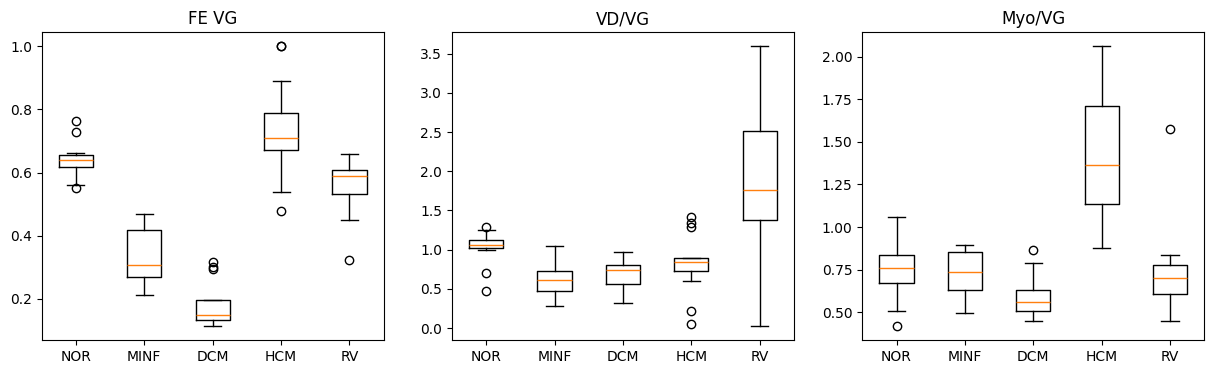

In [4]:
print('{:<6}'.format('') + ''.join('{:>9}'.format(f) for f in FEATURES))
for c, name in enumerate(CLASSES):
    print('{:<6}'.format(name) + ''.join('{:>9.2f}'.format(v) if v < 10 else '{:>9.0f}'.format(v) for v in X[y == c].mean(axis=0)))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, f in zip(axes, ['FE VG', 'VD/VG', 'Myo/VG']):
    ax.boxplot([X[y == c, FEATURES.index(f)] for c in range(len(CLASSES))])
    ax.set_xticks(range(1, len(CLASSES) + 1))
    ax.set_xticklabels(CLASSES)
    ax.set_title(f)
plt.show()

In [5]:
def train_classifier(x, t, weights):
    model = FeatureClassifier(x.shape[1], HIDDEN)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    ce_loss = nn.CrossEntropyLoss(weight=weights)
    for epoch in range(EPOCHS):
        model.train()
        loss = ce_loss(model(x), t)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return model


def train_ensemble(X, y):
    mean, std = X.mean(axis=0), X.std(axis=0) + 1e-6
    x = torch.tensor((X - mean) / std, dtype=torch.float32)
    t = torch.tensor(y)
    counts = np.bincount(y, minlength=len(CLASSES))
    weights = torch.tensor(len(y) / (len(CLASSES) * np.maximum(counts, 1)), dtype=torch.float32)
    models = [train_classifier(x, t, weights) for _ in range(ENSEMBLE)]
    return models, mean, std


@torch.no_grad()
def predict(models, mean, std, X):
    x = torch.tensor((X - mean) / std, dtype=torch.float32)
    probs = []
    for model in models:
        model.eval()
        probs.append(torch.softmax(model(x), dim=1))
    return torch.stack(probs).mean(dim=0).argmax(dim=1).numpy()

In [6]:
torch.manual_seed(SEED)
pred = np.zeros(len(patients), dtype=int)

for k in range(FOLDS):
    test = np.array([fold[p] == k for p in patients])
    models, mean, std = train_ensemble(X[~test], y[~test])
    pred[test] = predict(models, mean, std, X[test])
    print('Pli {} : {} / {} patients bien classés'.format(k, (pred[test] == y[test]).sum(), test.sum()))

print('Précision (validation croisée) : {} / {} = {:.3f}'.format((pred == y).sum(), len(y), (pred == y).mean()))
for c, name in enumerate(CLASSES):
    recall = (pred[y == c] == c).mean()
    precision = (y[pred == c] == c).mean() if (pred == c).any() else 0
    print('{:<5} rappel {:.2f}  précision {:.2f}'.format(name, recall, precision))

Pli 0 : 12 / 14 patients bien classés
Pli 1 : 10 / 13 patients bien classés
Pli 2 : 9 / 13 patients bien classés
Pli 3 : 13 / 13 patients bien classés
Pli 4 : 10 / 13 patients bien classés
Précision (validation croisée) : 54 / 66 = 0.818
NOR   rappel 0.87  précision 0.87
MINF  rappel 0.60  précision 0.90
DCM   rappel 0.92  précision 0.65
HCM   rappel 0.88  précision 0.88
RV    rappel 0.88  précision 0.88


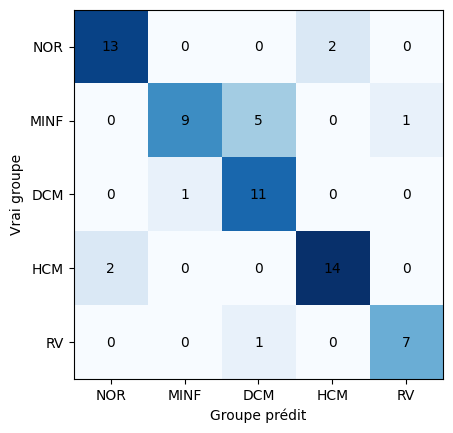

In [7]:
matrix = np.zeros((len(CLASSES), len(CLASSES)), dtype=int)
for t, p in zip(y, pred):
    matrix[t, p] += 1

plt.imshow(matrix, cmap='Blues')
for t in range(len(CLASSES)):
    for p in range(len(CLASSES)):
        plt.text(p, t, matrix[t, p], ha='center', va='center')
plt.xticks(range(len(CLASSES)), CLASSES)
plt.yticks(range(len(CLASSES)), CLASSES)
plt.xlabel('Groupe prédit')
plt.ylabel('Vrai groupe')
plt.show()

In [8]:
torch.manual_seed(SEED)
models, mean, std = train_ensemble(X, y)
os.makedirs('models', exist_ok=True)
torch.save({'models': [m.state_dict() for m in models], 'mean': mean, 'std': std}, MODEL_PATH)